# Pipeline final: B1 + cabeza CLIP + **nuevo modelo de profundidad** + cabeza nutricional (tabla + ajuste)

**Proyecto IA2 · conteo de calorías por foto**

Es la versión de entrega del pipeline. Respecto al notebook anterior:

| | Notebook anterior | Este notebook |
|---|---|---|
| Profundidad | DPT de la fase 1 | **Depth Anything V2 Metric (small)** afinado por tu compañero (`entrega/`) |
| Cabeza nutricional | seis variantes comparadas | **solo la elegida: densidad = tabla real + ajuste aprendido** (`table_ft`) |
| Datos de entrenamiento | todos los pendientes | sin los platos con etiqueta calórica inválida (kcal < 5 con masa > 20 g) |
| Evaluación | test aleatorio | **test solo con platos que ni la cabeza CLIP ni el modelo de profundidad vieron** |

```
foto RGB ─► B1 (regiones) ─► CLIP + cabeza A (clase de cada región) ─┐
   └─────► Depth Anything V2 afinado (metros) ─► altura / volumen ───┼─► cabeza nutricional ─► gramos por región
                                                                      │         │
                           tabla nutricional real + ajuste aprendido ◄─────────┘ ─► kcal, grasa, carb, proteína
```

Incluye una **comparación con profundidad anterior, sin profundidad y real** con bootstrap por plato. Esa comparación responde, con tus datos, si el nuevo modelo mejora de verdad el pipeline.

---

## Qué debe haber en tu carpeta

**Junto a este notebook:**

| Qué | De dónde sale |
|---|---|
| `cabeza_clip_A_s0.pt`, `_s1.pt`, `_s2.pt` | notebook de fine‑tuning |
| `dataset_A_minimo/manifest.csv`, `dataset_B_estricto/manifest.csv`, `clean_refs/manifest.csv` | exportación del autoetiquetado (solo los manifest) |
| *(opcional, ahorra ~10 min)* `pipeline_cache/` | del notebook anterior: se reutilizan las regiones y los embeddings, y la profundidad anterior y real |

**Fuera de la carpeta (rutas de la Parte 1):**

| Qué | Dónde |
|---|---|
| **`entrega/`** del compañero: `weights.pt`, `config.json`, `profundidad_n5k.py` | Drive: `…/Nutrition5k/profundidad_v2/entrega/` |
| **`split_v2.json`** del compañero | Drive: `…/Nutrition5k/profundidad_v2/split_v2.json` |
| `dish_metadata_cafe1.csv`, `dish_metadata_cafe2.csv`, `ingredients_metadata.csv` | `C:\nutrition5k\metadata\` |
| `realsense_overhead\<plato>\rgb.png` y `depth_raw.png` | `C:\nutrition5k\realsense_overhead\` |
| SegFormer‑B1 (`config.json` + `model.safetensors`) | `C:\foodseg_segformer\mit-b1\` |
| CLIP‑L/14 y `depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf` | caché de Hugging Face (se descargan la primera vez; `profundidad_n5k` baja la arquitectura y luego carga los pesos afinados) |

`split_v2.json` es imprescindible para una evaluación honesta: dice con qué platos se entrenó el modelo de profundidad.

## 1. Configuración

In [4]:
from pathlib import Path
import csv, json, time, math, random, warnings, hashlib, sys
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from PIL import Image

# ============ 🔧 RUTAS (ajústalas a tu PC) ============
N5K_ROOT   = Path(r"C:\nutrition5k")                                         # metadata/ y realsense_overhead/
SEG_DIR    = Path(r"C:\foodseg_segformer\mit-b1")                            # SegFormer-B1 (FoodSeg103)
DEPTH_DIR  = Path(r"C:\nutrition5k\entrega")                  # weights.pt + config.json + profundidad_n5k.py
DEPTH_SPLIT_FILE = Path(r"C:\nutrition5k\entrega\split_v2.json")      # train/val/test del modelo de profundidad
HEAD_DIR   = Path(".")                                                        # donde están cabeza_clip_*.pt
HEAD_TAG   = "A"                                                              # "A" o "B"
HEAD_FILES = [HEAD_DIR / f"cabeza_clip_{HEAD_TAG}_s{s}.pt" for s in (0, 1, 2)]
MANIFESTS  = [Path("dataset_A_minimo/manifest.csv"), Path("dataset_B_estricto/manifest.csv")]
REFS_MANIFEST = Path("clean_refs/manifest.csv")
CACHE_DIR  = Path("pipeline_cache"); CACHE_DIR.mkdir(exist_ok=True)           # puedes reutilizar la del notebook anterior

# ============ GEOMETRÍA / REGIONES (NO cambiar si reutilizas la caché del notebook anterior) ============
S             = 128
SEG_INPUT     = 512
SEG_MEAN, SEG_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
MIN_REGION_PX = 1500
R_MAX         = 16
BG_ID         = 0
IGNORE        = 255
DEPTH_UNIT    = 1e-4         # depth_raw.png -> metros
DEPTH_MAX_M   = 0.6
CLIP_CHUNK    = 16
CHUNK         = 250

DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
SEED    = 42
SEEDS   = [0, 1, 2]
MAX_DISHES = None            # p. ej. 60 para una prueba rápida (usa su propia caché)
TARGETS = ["mass", "kcal", "fat", "carb", "protein"]
UNITS   = ["g", "kcal", "g", "g", "g"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("device:", DEVICE)

device: cuda


## 2. Metadata y división de platos

Tres grupos **que no se pisan**:

- **Vistos por la cabeza CLIP** (train/val de A o B): se excluyen por completo.
- **Pendientes (U)**: el resto de platos. Se dividen según el **split del modelo de profundidad** (`split_v2.json`):
  - los que el modelo de profundidad **no vio** (su `test`) → **test de este notebook**,
  - los demás → entrenamiento (90 %) y validación (10 %) de la cabeza nutricional.
- **Set limpio**: los que caen en el test de profundidad se suman al test. Los demás **no se usan para entrenar**; se reportan aparte, con la advertencia de que el modelo de profundidad los vio.

Así el test mide lo que pasará con fotos nuevas, y la cabeza nutricional se entrena con la calidad de profundidad que el modelo tiene en platos ya conocidos (lo realista si luego se aplica a fotos nuevas).

**Etiquetas inválidas:** los platos con `kcal < 5` y `masa > 20 g` (comida visible con 0 kcal en la metadata) se quitan del entrenamiento, y en el test se enmascaran solo kcal, grasa, carbohidratos y proteína (la masa sigue valiendo).

In [5]:
def load_metadata(meta_dir):
    rows = []
    for fn in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
        p = meta_dir / fn
        if not p.exists():
            warnings.warn(f"no existe {p}"); continue
        with open(p, newline="", encoding="utf-8") as f:
            for r in csv.reader(f):
                if len(r) < 6: continue
                try:
                    dish, kcal, mass, fat, carb, prot = r[0], *[float(x) for x in r[1:6]]
                except ValueError:
                    continue
                rows.append([dish, mass, kcal, fat, carb, prot])          # reordeno a TARGETS
    return pd.DataFrame(rows, columns=["dish_id"] + TARGETS)

def load_depth_split(path):
    """split_v2.json del modelo de profundidad -> dict de conjuntos {train, val, test}; None si no existe."""
    if path is None or not Path(path).exists(): return None
    sp = json.loads(Path(path).read_text(encoding="utf-8"))
    return {k: {str(x) for x in sp.get(k, [])} for k in ("train", "val", "test")}

def make_splits(pool_u, pool_ref, depth_test, seed=SEED, val_frac=0.1):
    """pool_u: pendientes; pool_ref: set limpio; depth_test: platos de test del modelo de profundidad (o None).
    -> IDX (train/val/test sobre pool_u + pool_ref), REF_ALL (índices de todo el set limpio), GRP."""
    n_u, n_r = len(pool_u), len(pool_ref); all_d = list(pool_u) + list(pool_ref)
    u_idx, r_idx = np.arange(n_u), np.arange(n_u, n_u + n_r)
    grp = np.array(["u"] * n_u + ["refs"] * n_r)
    if depth_test is None:                                              # sin split de profundidad: 80/10/10 al azar (menos honesto)
        perm = np.random.default_rng(seed).permutation(n_u)
        a, b = int(n_u * 0.8), int(n_u * 0.9)
        return dict(train=perm[:a], val=perm[a:b], test=np.r_[perm[b:], r_idx]), r_idx, grp
    is_t = np.array([d in depth_test for d in all_d])
    rest = u_idx[~is_t[:n_u]]
    perm = np.random.default_rng(seed).permutation(rest)
    n_val = int(round(len(perm) * val_frac))
    idx = dict(train=perm[n_val:], val=perm[:n_val], test=np.r_[u_idx[is_t[:n_u]], r_idx[is_t[n_u:]]])
    return idx, r_idx, grp

img_root = N5K_ROOT / "realsense_overhead"
df = load_metadata(N5K_ROOT / "metadata")
have = {p.name for p in img_root.iterdir() if (p / "rgb.png").exists()}
df = df[df.dish_id.isin(have) & (df.mass > 5)].drop_duplicates("dish_id").reset_index(drop=True)
ratio = (df.kcal / df.mass).median()
assert 0.3 < ratio < 5, f"kcal/masa mediana = {ratio:.2f}: revisa el orden de columnas del CSV"

seen = set()
for m in MANIFESTS:
    man = pd.read_csv(m, keep_default_na=False, dtype=str)
    seen |= set(man[man.split.isin(["train", "val"])].dish)
refs = pd.read_csv(REFS_MANIFEST, keep_default_na=False, dtype=str)
REF_SET = set(refs.dish)
assert not (seen & REF_SET), "hay platos del set limpio en train/val de la cabeza CLIP"

pool_u   = [d for d in df.dish_id if d not in seen and d not in REF_SET]
pool_ref = [d for d in df.dish_id if d in REF_SET]
if MAX_DISHES:
    pool_u, pool_ref = pool_u[:MAX_DISHES], pool_ref[:20]
dishes = pool_u + pool_ref
KEY = hashlib.md5(",".join(dishes).encode()).hexdigest()[:8]               # identifica esta lista de platos en la caché

DEPTH_SPLIT = load_depth_split(DEPTH_SPLIT_FILE)
IDX, REF_ALL, GRP = make_splits(pool_u, pool_ref, DEPTH_SPLIT["test"] if DEPTH_SPLIT else None)
Y = df.set_index("dish_id").loc[dishes, TARGETS].values.astype(np.float32)

BAD = (Y[:, 1] < 5) & (Y[:, 0] > 20)                                         # etiqueta calórica inválida
n_bad_tr = int(BAD[IDX["train"]].sum()) + int(BAD[IDX["val"]].sum())
IDX["train"] = IDX["train"][~BAD[IDX["train"]]]; IDX["val"] = IDX["val"][~BAD[IDX["val"]]]

print(f"{len(df)} platos con imagen y metadata | kcal/g mediana = {ratio:.2f}")
print(f"vistos por la cabeza CLIP (excluidos): {len(seen)} | pendientes: {len(pool_u)} | set limpio: {len(pool_ref)}")
print({k: len(v) for k, v in IDX.items()}, f"| quitados de train/val por etiqueta inválida: {n_bad_tr}")
if DEPTH_SPLIT is None:
    print("⚠ NO se encontró DEPTH_SPLIT_FILE: el test es aleatorio y puede incluir platos con los que se entrenó la profundidad (optimista).")
else:
    print(f"profundidad: {len(DEPTH_SPLIT['train'])} train · {len(DEPTH_SPLIT['val'])} val · {len(DEPTH_SPLIT['test'])} test")
    print(f"set limpio: {int(np.isin(np.array(pool_ref), list(DEPTH_SPLIT['test'])).sum())} de {len(pool_ref)} caen en el test de profundidad (van al test); el resto solo se reporta aparte")

3485 platos con imagen y metadata | kcal/g mediana = 1.05
vistos por la cabeza CLIP (excluidos): 1242 | pendientes: 2203 | set limpio: 40
{'train': 1551, 'val': 171, 'test': 372} | quitados de train/val por etiqueta inválida: 114
profundidad: 2590 train · 290 val · 580 test
set limpio: 5 de 40 caen en el test de profundidad (van al test); el resto solo se reporta aparte


## 3. Los modelos como adaptadores (todos congelados)

B1, CLIP y las cabezas son los mismos del notebook anterior. **Cambia la profundidad:** se carga el módulo `profundidad_n5k.py` y los pesos que exportó tu compañero.

`predict_depth` devuelve metros al tamaño original de la foto (con TTA = promedio con la imagen volteada, como en sus métricas). Se reduce a la rejilla de 128×128 con el mismo promedio por área que usaba el pipeline.

In [6]:
from transformers import SegformerForSemanticSegmentation, CLIPModel, CLIPProcessor

# ---------- Cabeza(s) CLIP: clases y pesos ----------
HEAD_CKS = [torch.load(f, map_location="cpu", weights_only=False) for f in HEAD_FILES]
CLASSES = HEAD_CKS[0]["classes"]                  # ["background", clase1, ..., claseK]
K = len(CLASSES) - 1
assert all(ck["classes"] == CLASSES for ck in HEAD_CKS), "las cabezas tienen clases distintas"
CLIP_NAME = HEAD_CKS[0]["clip_name"]
HEADS_WB = [(ck["linear"]["weight"].float().to(DEVICE), ck["linear"]["bias"].float().to(DEVICE)) for ck in HEAD_CKS]
print(f"{len(HEAD_CKS)} cabezas | {K} clases | CLIP: {CLIP_NAME}")

# ---------- SegFormer-B1 ----------
seg_model = SegformerForSemanticSegmentation.from_pretrained(str(SEG_DIR)).to(DEVICE).eval()
for p in seg_model.parameters(): p.requires_grad_(False)
C_SEG = seg_model.config.num_labels
id2label = {int(k): v for k, v in seg_model.config.id2label.items()}
SEG_MEAN_T = torch.tensor(SEG_MEAN, device=DEVICE).view(1, 3, 1, 1)
SEG_STD_T  = torch.tensor(SEG_STD,  device=DEVICE).view(1, 3, 1, 1)
print("clases del segmentador:", C_SEG, "| fondo:", id2label.get(BG_ID))

# ---------- CLIP ----------
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_proc  = CLIPProcessor.from_pretrained(CLIP_NAME)
clip_dtype = next(clip_model.parameters()).dtype
CLIP_DIM   = clip_model.config.projection_dim
_DUMMY_TXT = clip_proc(text=["a"], return_tensors="pt", padding=True).to(DEVICE)

@torch.no_grad()
def embed_crops(crops):
    feats = []
    for i in range(0, len(crops), CLIP_CHUNK):
        pv = clip_proc(images=crops[i:i + CLIP_CHUNK], return_tensors="pt")["pixel_values"]
        out = clip_model(**_DUMMY_TXT, pixel_values=pv.to(DEVICE, clip_dtype))
        feats.append(F.normalize(out.image_embeds.float(), dim=-1))
    return torch.cat(feats) if feats else torch.zeros(0, CLIP_DIM, device=DEVICE)

def make_crop(img, mask, masked=True, pad=10, square=True):
    ys, xs = np.where(mask)
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, img.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, img.shape[1])
    crop = img[y0:y1, x0:x1].copy()
    if masked:
        crop[~mask[y0:y1, x0:x1]] = 127
    if square:
        h, w = crop.shape[:2]; s = max(h, w)
        canvas = np.full((s, s, 3), 127, np.uint8)
        oy, ox = (s - h) // 2, (s - w) // 2
        canvas[oy:oy + h, ox:ox + w] = crop
        crop = canvas
    return Image.fromarray(crop)

def embed_regions(img, rm):
    """(R, CLIP_DIM) float16: media normalizada de recorte enmascarado + caja completa. rm: ids 1..R."""
    R = int(rm.max())
    if R == 0: return np.zeros((0, CLIP_DIM), np.float16)
    masks = [rm == i for i in range(1, R + 1)]
    fm = embed_crops([make_crop(img, m, masked=True) for m in masks])
    fb = embed_crops([make_crop(img, m, masked=False) for m in masks])
    return F.normalize(fm + fb, dim=-1).cpu().numpy().astype(np.float16)

@torch.no_grad()
def clip_head_probs(emb):
    """(M, CLIP_DIM) -> (M, K): softmax de cada cabeza, promediado sobre las semillas."""
    x = F.normalize(torch.from_numpy(np.asarray(emb, np.float32)).to(DEVICE), dim=-1)
    out = sum((x @ W.T + b).softmax(-1) for W, b in HEADS_WB) / len(HEADS_WB)
    return out.cpu().numpy()

# ---------- Profundidad: Depth Anything V2 afinado (módulo y pesos de la carpeta `entrega/`) ----------
sys.path.insert(0, str(DEPTH_DIR))
import profundidad_n5k as pn
DEPTH_NET = pn.load_model(str(DEPTH_DIR), device=DEVICE)          # la primera vez baja la arquitectura de Hugging Face y carga weights.pt
DEPTH_CFG = json.loads((DEPTH_DIR / "config.json").read_text(encoding="utf-8"))
_m = DEPTH_CFG.get("info", {}).get("metricas_test", {})
_m = _m.get("tta", _m.get("sin_tta", {}))
print("profundidad:", DEPTH_CFG["key"], "| experimento:", DEPTH_CFG.get("info", {}).get("run"))
print("   métricas del compañero en su test (580 platos):", {k: round(v, 4) for k, v in _m.items() if k in ("abs_rel", "mae_mm", "mae_altura_mm", "err_vol_mediana_pct")})

@torch.no_grad()
def depth_from_pil(pil_img, tta=True):
    """Foto RGB original -> profundidad en METROS reducida a SxS."""
    d = pn.predict_depth(DEPTH_NET, pil_img.convert("RGB"), tta=tta)
    t = torch.from_numpy(np.asarray(d, np.float32))[None, None]
    return F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy()

def depth_from_gt(dish_dir):
    """depth_raw.png -> metros (inválidos rellenados con el vecino válido más cercano) reducido a SxS."""
    raw = np.array(Image.open(Path(dish_dir) / "depth_raw.png")).astype(np.float32)
    valid = (raw > 0) & (raw < 65535) & (raw * DEPTH_UNIT < DEPTH_MAX_M)
    d = raw * DEPTH_UNIT
    if valid.any() and not valid.all():
        idx = ndi.distance_transform_edt(~valid, return_distances=False, return_indices=True)
        d = d[tuple(idx)]
    elif not valid.any():
        d = np.full_like(d, 0.36)
    t = torch.from_numpy(d.astype(np.float32))[None, None]
    return F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy()

3 cabezas | 67 clases | CLIP: openai/clip-vit-large-patch14


Loading weights: 100%|██████████| 208/208 [00:00<00:00, 3131.93it/s]


clases del segmentador: 104 | fondo: background


Loading weights: 100%|██████████| 590/590 [00:02<00:00, 212.83it/s]
c:\Users\mjcor\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mjcor\.cache\huggingface\hub\models--depth-anything--Depth-Anything-V2-Metric-Indoor-Small-hf. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn

profundidad: da2_small | experimento: da2_small_v1
   métricas del compañero en su test (580 platos): {'abs_rel': 0.0099, 'mae_mm': 3.6794, 'mae_altura_mm': 5.1574, 'err_vol_mediana_pct': 12.8349}


## 4. De la foto a *features por región*

Mismas funciones del notebook anterior (regiones por componentes conectados, altura sobre el plano de la mesa y volumen relativo por región, y la tabla nutricional por nombre de clase). Se mantienen idénticas a propósito: así se reutiliza la caché y la comparación con el pipeline anterior es limpia.

In [7]:
GEOM_NAMES = ["area_frac", "h_mean_cm", "h_std_cm", "h_p90_cm", "vol"]
GLOB_NAMES = ["plane_cm", "food_frac", "n_regions", "h_mean_all_cm", "vol_total"]
N_GEOM, N_GLOB = len(GEOM_NAMES), len(GLOB_NAMES)

def grid_index(n_src, n_dst=S):
    return np.minimum(((np.arange(n_dst) + 0.5) * n_src / n_dst).astype(int), n_src - 1)

def components(class_map, min_px=MIN_REGION_PX):
    """Componentes conectados de cada clase (ignora 0 = fondo y 255). -> (region_map uint16, clase de origen por región)."""
    rm = np.zeros(class_map.shape, np.uint16); src = []
    for c in np.unique(class_map):
        if c == BG_ID or c == IGNORE: continue
        comp, n = ndi.label(class_map == c)
        if n == 0: continue
        areas = np.bincount(comp.ravel())[1:]
        for k in np.nonzero(areas >= min_px)[0] + 1:
            src.append(int(c)); rm[comp == k] = len(src)
    return rm, src

def top_regions(rm, src, r_max=R_MAX):
    """Conserva las r_max regiones más grandes y las renumera 1..n por área descendente."""
    if not src: return rm.astype(np.uint8), src
    areas = np.bincount(rm.ravel().astype(np.int64))[1:]
    order = np.argsort(-areas, kind="stable")[:r_max]
    new = np.zeros(rm.shape, np.uint8)
    for nid, old in enumerate(order, start=1):
        new[rm == old + 1] = nid
    return new, [src[o] for o in order]

def region_features(rm, bg, depth_m, n, r_max=R_MAX, return_height=False):
    """rm: (S,S) ids 1..n · bg: (S,S) bool (fondo según B1) · depth_m: (S,S) metros. -> G (r_max,5), M (r_max,) bool, GL (5,)"""
    H, W = rm.shape; tot = float(H * W)
    plane = np.median(depth_m[bg]) if bg.sum() >= 200 else np.percentile(depth_m, 95)
    height_cm = np.clip(plane - depth_m, 0, None) * 100.0
    G = np.zeros((r_max, N_GEOM), np.float32); M = np.zeros(r_max, bool)
    for r in range(min(n, r_max)):
        m = rm == r + 1
        if not m.any(): continue
        h = height_cm[m]
        G[r] = [m.sum() / tot, h.mean(), h.std(), np.percentile(h, 90), h.sum() / tot]; M[r] = True
    food = rm > 0
    GL = np.array([plane * 100.0, food.mean(), n / r_max,
                   height_cm[food].mean() if food.any() else 0.0,
                   height_cm[food].sum() / tot], np.float32)
    return (G, M, GL, height_cm) if return_height else (G, M, GL)

def load_density_table(meta_dir, class_names):
    """Densidad por gramo [kcal, grasa, carb, prot] de cada clase, buscando su nombre en ingredients_metadata.csv. NaN si no está."""
    ing = pd.read_csv(Path(meta_dir) / "ingredients_metadata.csv")
    cols = {c.strip().lower(): c for c in ing.columns}
    pick = lambda pref: next(cols[c] for c in cols if c.startswith(pref))
    name_c, cal_c, fat_c, carb_c, prot_c = pick("ingr"), pick("cal"), pick("fat"), pick("carb"), pick("prot")
    t = ing.assign(_n=ing[name_c].astype(str).str.strip().str.lower()).drop_duplicates("_n").set_index("_n")
    rows = []
    for n in class_names:
        k = n.strip().lower()
        rows.append([float(t.loc[k, cal_c]), float(t.loc[k, fat_c]), float(t.loc[k, carb_c]), float(t.loc[k, prot_c])]
                    if k in t.index else [np.nan] * 4)
    return np.array(rows, np.float32)

## 5. Extracción con caché por tandas

- **Etapa A (B1 + CLIP):** regiones, fondo, embeddings y probabilidades de B1. Si copiaste `pipeline_cache/` del notebook anterior, se **reutiliza** (nombre `stageA`; no recalcula nada).
- **Profundidad nueva (`depth_da2`):** el modelo afinado sobre todos los platos de la lista.
- **Profundidad real (`depth_gt`):** de `depth_raw.png`. Se reutiliza si ya existe.
- **Profundidad anterior (`depth_model`):** solo si existe en la caché del notebook anterior (se usa para comparar; aquí no se recalcula).

In [8]:
def load_rgb(dish):
    return np.array(Image.open(img_root / dish / "rgb.png").convert("RGB"))

@torch.no_grad()
def b1_forward(img):
    """-> probs (C,S,S) y mapa de clases a resolución original (uint8, 0 = fondo)."""
    H, W = img.shape[:2]
    x = torch.from_numpy(np.array(Image.fromarray(img).resize((SEG_INPUT, SEG_INPUT), Image.BILINEAR)))
    x = (x.to(DEVICE).permute(2, 0, 1)[None].float() / 255.0 - SEG_MEAN_T) / SEG_STD_T
    lg = seg_model(pixel_values=x).logits
    if lg.shape[-1] != S:
        lg = F.interpolate(lg, size=(S, S), mode="bilinear", align_corners=False)
    probs = lg.softmax(1)[0].cpu().numpy()
    full = F.interpolate(lg, size=(H, W), mode="bilinear", align_corners=False).argmax(1)[0].cpu().numpy().astype(np.uint8)
    return probs, full

def stage_a(img):
    probs, full = b1_forward(img)
    rm, src = components(full)
    rm, src = top_regions(rm, src)
    n = len(src); H, W = img.shape[:2]
    emb = np.zeros((R_MAX, CLIP_DIM), np.float16)
    if n: emb[:n] = embed_regions(img, rm)
    rm128 = rm[np.ix_(grid_index(H), grid_index(W))]
    pb1 = np.zeros((R_MAX, probs.shape[0]), np.float16)
    for r in range(n):
        m = rm128 == r + 1
        if m.any(): pb1[r] = probs[:, m].mean(1)
    return dict(rm=rm128.astype(np.uint8), bg=probs.argmax(0) == BG_ID, emb=emb, n=n, pb1=pb1)

def stage_a_chunk(ids):
    outs = [stage_a(load_rgb(d)) for d in ids]
    return {k: np.stack([o[k] for o in outs]) for k in ("rm", "bg", "emb", "n", "pb1")}

def depth_chunk(mode):
    def fn(ids):
        if mode == "gt":
            return dict(depth=np.stack([depth_from_gt(img_root / d) for d in ids]))
        return dict(depth=np.stack([depth_from_pil(Image.open(img_root / d / "rgb.png")) for d in ids]))   # "da2"
    return fn

def cached_chunks(name, dish_list, fn, chunk=CHUNK):
    d = CACHE_DIR / f"{name}_{KEY}"; d.mkdir(parents=True, exist_ok=True)
    parts, t0 = [], time.time()
    for ci, i in enumerate(range(0, len(dish_list), chunk)):
        f = d / f"chunk_{ci:04d}.npz"
        if not f.exists():
            np.savez_compressed(f, **fn(dish_list[i:i + chunk]))
            print(f"  {name}: {min(i + chunk, len(dish_list))}/{len(dish_list)}  ({time.time() - t0:.0f} s)")
        z = np.load(f); parts.append({k: z[k] for k in z.files})
    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}

def load_cached(name):
    """Devuelve el array 'depth' de una caché completa, o None si falta o está incompleta."""
    d = CACHE_DIR / f"{name}_{KEY}"
    files = sorted(d.glob("chunk_*.npz")) if d.exists() else []
    if len(files) != math.ceil(len(dishes) / CHUNK): return None
    return np.concatenate([np.load(f)["depth"] for f in files])

A = cached_chunks("stageA", dishes, stage_a_chunk)

DEPTH = {"da2": cached_chunks("depth_da2", dishes, depth_chunk("da2"))["depth"]}
gt = load_cached("depth_gt")
DEPTH["gt"] = gt if gt is not None else cached_chunks("depth_gt", dishes, depth_chunk("gt"))["depth"]
old_dpt = load_cached("depth_model")
if old_dpt is not None:
    DEPTH["dpt_old"] = old_dpt
else:
    print("⚠ no hay caché de la profundidad anterior (depth_model): se omite esa comparación")

print("regiones por plato: media %.1f, máx %d, platos sin regiones: %d" % (A["n"].mean(), A["n"].max(), (A["n"] == 0).sum()))
for k, v in DEPTH.items():
    print(f"profundidad {k}: mediana {np.median(v):.3f} m (esperado ~0.30-0.40)")

# comprobación de que el modelo de profundidad cargó bien: error frente a la real en platos de TEST (rejilla 128)
te = IDX["test"]
for k in [k for k in DEPTH if k != "gt"]:
    print(f"error de profundidad {k:8s} vs real en test: MAE {1000 * np.abs(DEPTH[k][te] - DEPTH['gt'][te]).mean():.1f} mm")
print("  (el da2 debería quedar en unos pocos mm; si sale > 15 mm, revisa DEPTH_DIR, el TTA o el orden de los platos)")

  depth_da2: 250/2243  (21 s)
  depth_da2: 500/2243  (42 s)
  depth_da2: 750/2243  (63 s)
  depth_da2: 1000/2243  (82 s)
  depth_da2: 1250/2243  (103 s)
  depth_da2: 1500/2243  (125 s)
  depth_da2: 1750/2243  (146 s)
  depth_da2: 2000/2243  (167 s)
  depth_da2: 2243/2243  (189 s)
regiones por plato: media 3.9, máx 16, platos sin regiones: 10
profundidad da2: mediana 0.362 m (esperado ~0.30-0.40)
profundidad gt: mediana 0.361 m (esperado ~0.30-0.40)
profundidad dpt_old: mediana 0.366 m (esperado ~0.30-0.40)
error de profundidad da2      vs real en test: MAE 5.6 mm
error de profundidad dpt_old  vs real en test: MAE 21.4 mm
  (el da2 debería quedar en unos pocos mm; si sale > 15 mm, revisa DEPTH_DIR, el TTA o el orden de los platos)


## 6. Features, clases y tabla nutricional

- **Geometría:** una por cada fuente de profundidad disponible (nueva, anterior, real).
- **Clases `P`:** cabeza CLIP (K clases), promediada sobre las 3 semillas.
- **Tabla nutricional real:** densidad por gramo (kcal, grasa, carb, proteína) desde `ingredients_metadata.csv`, por nombre de clase. Lo que no se encuentra usa la razón global del dataset.

In [9]:
def build_geometry(depth):
    n_d = len(dishes); G = np.zeros((n_d, R_MAX, N_GEOM), np.float32)
    M = np.zeros((n_d, R_MAX), bool); GL = np.zeros((n_d, N_GLOB), np.float32)
    for i in range(n_d):
        G[i], M[i], GL[i] = region_features(A["rm"][i], A["bg"][i], depth[i], int(A["n"][i]))
    return G, M, GL

GEO = {k: build_geometry(v) for k, v in DEPTH.items()}
M_ALL = GEO["da2"][1]
assert all((g[1] == M_ALL).all() for g in GEO.values()), "las máscaras de región no dependen de la profundidad"

P_head = np.zeros((len(dishes), R_MAX, K), np.float16)
P_head[M_ALL] = clip_head_probs(A["emb"][M_ALL]).astype(np.float16)

tab = load_density_table(N5K_ROOT / "metadata", CLASSES[1:])
tr = IDX["train"]
PRIOR_GLOBAL = (Y[tr, 1:].sum(0) / Y[tr, 0].sum()).astype(np.float32)
miss = np.isnan(tab[:, 0])
DENS_TABLE = np.where(np.isnan(tab), PRIOR_GLOBAL[None, :], tab).astype(np.float32)
print(f"tabla nutricional: {K - int(miss.sum())}/{K} clases encontradas por nombre | razón global: {np.round(PRIOR_GLOBAL, 3)}")
if miss.any():
    print("sin coincidencia (usan la razón global):", [CLASSES[1 + i] for i in np.nonzero(miss)[0]])
print("kcal/g de la tabla: min %.2f, mediana %.2f, max %.2f" % (DENS_TABLE[:, 0].min(), np.median(DENS_TABLE[:, 0]), DENS_TABLE[:, 0].max()))

tabla nutricional: 65/67 clases encontradas por nombre | razón global: [1.204 0.061 0.092 0.082]
sin coincidencia (usan la razón global): ['', 'leafy greens']
kcal/g de la tabla: min 0.10, mediana 0.91, max 5.78


## 7. La cabeza nutricional y las variantes que se comparan

Misma cabeza del notebook anterior (gramos por región ≥ 0; los totales son la suma sobre regiones, que es lo único que Nutrition5k etiqueta). **La elegida es `tabla + ajuste`:** la densidad de cada clase es `tabla_real × exp(Δ)`, con un `Δ` aprendido por clase que parte de 0 y se penaliza para no alejarse de la tabla.

Todas las variantes usan **la misma cabeza y la misma densidad (tabla + ajuste)**; solo cambia la fuente de profundidad, para aislar el efecto del nuevo modelo:

| Variante | Profundidad |
|---|---|
| A | **ninguna** (solo área de cada región y tamaño del plato) |
| B | modelo anterior (DPT de la fase 1), solo si hay caché |
| **C ← final** | **modelo nuevo (Depth Anything V2 afinado)** |
| D | modelo nuevo, pero densidad = tabla sin ajuste (para confirmar que el ajuste sigue ayudando) |
| E | profundidad **real** (`depth_raw.png`): cota superior, no una cifra de producto |

In [10]:
class NutritionHead(nn.Module):
    def __init__(self, n_classes, prior, hidden=128, emb=32, drop=0.1, use_depth=True, mass_scale=100.0,
                 dens_mode="learned", table=None):
        super().__init__()
        self.cls_emb = nn.Linear(n_classes, emb, bias=False)
        self.enc = nn.Sequential(
            nn.Linear(emb + N_GEOM + N_GLOB, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, hidden), nn.GELU(),
            nn.Linear(hidden, 1))
        self.dens_mode = dens_mode
        if dens_mode in ("learned", "table_ft"):
            self.log_dens = nn.Parameter(torch.zeros(n_classes, 4))
        if dens_mode in ("table", "table_ft"):
            self.register_buffer("table", torch.as_tensor(table, dtype=torch.float32))
        self.register_buffer("prior", torch.as_tensor(prior, dtype=torch.float32))      # (4,) por gramo
        self.mass_scale = mass_scale
        gkeep  = torch.tensor([1, 0, 0, 0, 0], dtype=torch.float32) if not use_depth else torch.ones(N_GEOM)
        glkeep = torch.tensor([0, 1, 1, 0, 0], dtype=torch.float32) if not use_depth else torch.ones(N_GLOB)
        self.register_buffer("gkeep", gkeep); self.register_buffer("glkeep", glkeep)

    def densities(self):
        if self.dens_mode == "learned": return torch.exp(self.log_dens) * self.prior
        if self.dens_mode == "table":   return self.table
        return self.table * torch.exp(self.log_dens)

    def forward(self, P, G, GL, M):
        e = self.cls_emb(P)
        g = GL[:, None, :].expand(-1, P.size(1), -1) * self.glkeep
        h = torch.cat([e, G * self.gkeep, g], dim=-1)
        grams = F.softplus(self.enc(h).squeeze(-1)) * self.mass_scale * M
        dens = P @ self.densities()                                                  # (B,R,4) por gramo
        macros = (grams[..., None] * dens).sum(1)
        total = torch.cat([grams.sum(1, keepdim=True), macros], dim=1)               # [masa, kcal, grasa, carb, prot]
        return dict(total=total, grams=grams, dens=dens)

CFG = dict(hidden=128, emb=32, drop=0.1, lr=2e-3, wd=1e-3, bs=64, epochs=150, patience=25, dens_reg=1e-2, ft_reg=1e-1)

def fit_norm(cache, tr_idx):
    G, M, GL, Yt = cache["G"][tr_idx], cache["M"][tr_idx], cache["GL"][tr_idx], cache["Y"][tr_idx]
    gv = G[M]
    prior = (Yt[:, 1:].sum(0) / Yt[:, 0].sum()).astype(np.float32)
    return dict(g_mean=gv.mean(0), g_std=np.maximum(gv.std(0), 1e-6), gl_mean=GL.mean(0), gl_std=np.maximum(GL.std(0), 1e-6),
                y_scale=Yt.mean(0).astype(np.float32), prior=prior)

def apply_norm(P, G, M, GL, norm):
    Gn = (G - norm["g_mean"]) / norm["g_std"] * M[..., None]
    GLn = (GL - norm["gl_mean"]) / norm["gl_std"]
    return P.astype(np.float32), Gn.astype(np.float32), M.astype(np.float32), GLn.astype(np.float32)

def to_tensors(cache, idx, norm):
    P, G, M, GL = apply_norm(cache["P"][idx], cache["G"][idx], cache["M"][idx], cache["GL"][idx], norm)
    t = lambda a: torch.from_numpy(a).to(DEVICE)
    return dict(P=t(P), G=t(G), M=t(M), GL=t(GL), Y=t(cache["Y"][idx]))

def metrics(y, yhat):
    mae = np.abs(y - yhat).mean(0)
    return dict(mae=mae, pct=mae / y.mean(0) * 100.0)

@torch.no_grad()
def predict_tensors(model, T):
    model.eval()
    return model(T["P"], T["G"], T["GL"], T["M"])["total"].cpu().numpy()

def train_nutrition(Ttr, Tva, norm, n_classes, cfg=CFG, use_depth=True, dens_mode="learned", table=None, seed=SEED):
    set_seed(seed)
    model = NutritionHead(n_classes, norm["prior"], cfg["hidden"], cfg["emb"], cfg["drop"], use_depth, dens_mode=dens_mode, table=table).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    ys = torch.as_tensor(norm["y_scale"], device=DEVICE)
    reg_w = cfg["dens_reg"] if dens_mode == "learned" else cfg["ft_reg"]
    n = Ttr["P"].shape[0]; best, best_state, bad = 1e9, None, 0
    for ep in range(cfg["epochs"]):
        model.train(); perm = torch.randperm(n, device=DEVICE)
        for b in range(0, n, cfg["bs"]):
            ix = perm[b:b + cfg["bs"]]
            out = model(Ttr["P"][ix], Ttr["G"][ix], Ttr["GL"][ix], Ttr["M"][ix])
            loss = F.l1_loss(out["total"] / ys, Ttr["Y"][ix] / ys)
            if hasattr(model, "log_dens"):
                loss = loss + reg_w * (model.log_dens ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        val = metrics(Tva["Y"].cpu().numpy(), predict_tensors(model, Tva))["pct"].mean()
        if val < best - 1e-3:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if bad >= cfg["patience"]: break
    model.load_state_dict(best_state)
    return model, best

In [11]:
EXPERIMENTS = [
    ("A. sin profundidad · tabla+ajuste",        dict(depth="none",    dens="table_ft")),
    ("B. DPT anterior · tabla+ajuste",           dict(depth="dpt_old", dens="table_ft")),
    ("C. DA2 nuevo · tabla+ajuste  ← FINAL",     dict(depth="da2",     dens="table_ft")),
    ("D. DA2 nuevo · tabla (sin ajuste)",        dict(depth="da2",     dens="table")),
    ("E. prof. real · tabla+ajuste (cota)",      dict(depth="gt",      dens="table_ft")),
]
EXPERIMENTS = [(n, kw) for n, kw in EXPERIMENTS if kw["depth"] in ("none", *DEPTH.keys())]
NAME_FINAL = next(n for n, _ in EXPERIMENTS if "FINAL" in n)

def make_cache(depth):
    G, M, GL = GEO["da2" if depth == "none" else depth]
    return dict(P=P_head, G=G, M=M, GL=GL, Y=Y)

def run_variant(depth, dens):
    cache = make_cache(depth)
    norm = fit_norm(cache, IDX["train"])
    sets = dict(train=IDX["train"], val=IDX["val"], test=IDX["test"], refs=REF_ALL)
    T = {k: to_tensors(cache, v, norm) for k, v in sets.items()}
    runs = []
    for s in SEEDS:
        model, best = train_nutrition(T["train"], T["val"], norm, K, CFG, use_depth=(depth != "none"), dens_mode=dens,
                                      table=DENS_TABLE, seed=s)
        runs.append(dict(seed=s, val=best, pred=predict_tensors(model, T["test"]),
                         pred_refs=predict_tensors(model, T["refs"]), model=model, norm=norm))
    return runs

RESULTS = {}
t0 = time.time()
for name, kw in EXPERIMENTS:
    RESULTS[name] = run_variant(**kw)
    print(f"{name}: val %MAE {np.mean([r['val'] for r in RESULTS[name]]):.2f} ({time.time() - t0:.0f} s)")

A. sin profundidad · tabla+ajuste: val %MAE 27.15 (51 s)
B. DPT anterior · tabla+ajuste: val %MAE 28.10 (76 s)
C. DA2 nuevo · tabla+ajuste  ← FINAL: val %MAE 24.36 (118 s)
D. DA2 nuevo · tabla (sin ajuste): val %MAE 26.03 (142 s)
E. prof. real · tabla+ajuste (cota): val %MAE 23.43 (189 s)


## 8. Resultados

**%MAE** (error absoluto medio relativo a la media del target; menor es mejor), promedio ± desviación entre semillas. La **masa** se evalúa con todos los platos; **kcal, grasa, carbohidratos y proteína** solo con etiqueta válida. Se añade la **mediana del error absoluto**, que casi no se mueve por platos raros.

- **test (profundidad no lo vio):** el número que cuenta.
- **set limpio completo:** informativo. El modelo de profundidad vio la mayoría de esos platos, así que su profundidad se ve mejor de lo que será en fotos nuevas.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

YTE,  BAD_TE  = Y[IDX["test"]], BAD[IDX["test"]]
YREF, BAD_REF = Y[REF_ALL],    BAD[REF_ALL]

def metrics_masked(y, yhat, bad):
    """masa con todos los platos; kcal, grasa, carb y proteína solo con etiqueta válida. -> %MAE, MAE, mediana del error"""
    pct, mae, med = np.zeros(5), np.zeros(5), np.zeros(5)
    for k in range(5):
        m = np.ones(len(y), bool) if k == 0 else ~bad
        e = np.abs(y[m, k] - yhat[m, k])
        pct[k], mae[k], med[k] = e.mean() / y[m, k].mean() * 100, e.mean(), np.median(e)
    return pct, mae, med

def aggregates(idx):
    G, M, GL = GEO["da2"]
    return np.c_[(G[idx][..., 0] * M[idx]).sum(1), (G[idx][..., 4] * M[idx]).sum(1), GL[idx][:, 0], GL[idx][:, 3], GL[idx][:, 2]]

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(aggregates(IDX["train"]), Y[IDX["train"]])
ymean = Y[IDX["train"]].mean(0)
SUBSETS = {"test (profundidad no lo vio)": (YTE, BAD_TE, "pred", IDX["test"]),
           "set limpio completo (profundidad lo vio en su mayoría)": (YREF, BAD_REF, "pred_refs", REF_ALL)}

for sname, (y, bad, key, idx) in SUBSETS.items():
    base = {"Media": np.tile(ymean, (len(y), 1)), "Ridge (agregados)": ridge.predict(aggregates(idx))}
    rows, med_rows = {}, {}
    for k, p in base.items():
        pct, _, med = metrics_masked(y, p, bad); rows[k] = (pct, np.zeros(5)); med_rows[k] = med
    for name, runs in RESULTS.items():
        outs = [metrics_masked(y, r[key], bad) for r in runs]
        a = np.stack([o[0] for o in outs]); rows[name] = (a.mean(0), a.std(0))
        med_rows[name] = np.mean([o[2] for o in outs], axis=0)
    t = pd.DataFrame({k: [f"{m:.1f} ± {s:.1f}" if s > 0 else f"{m:.1f}" for m, s in zip(*v)] for k, v in rows.items()}, index=TARGETS).T
    t["promedio"] = [f"{np.mean(v[0]):.1f}" for v in rows.values()]
    t["mediana error masa (g)"] = [f"{v[0]:.0f}" for v in med_rows.values()]
    t["mediana error kcal"] = [f"{v[1]:.0f}" for v in med_rows.values()]
    print(f"\n=== %MAE · {sname} · {len(y)} platos ({int(bad.sum())} sin kcal válida) ===")
    display(t)


=== %MAE · test (profundidad no lo vio) · 372 platos (24 sin kcal válida) ===


,mass,kcal,fat,carb,protein,promedio,mediana error masa (g),mediana error kcal
Media,61.4,70.8,85.4,72.0,94.4,76.8,100,144
Ridge (agregados),32.3,51.4,71.8,62.2,72.1,58.0,37,87
A. sin profundidad · tabla+ajuste,21.7 ± 0.3,25.4 ± 0.1,33.5 ± 0.2,28.8 ± 0.0,30.7 ± 0.3,28.0,23,29
B. DPT anterior · tabla+ajuste,21.3 ± 0.3,26.0 ± 0.3,34.0 ± 0.2,29.0 ± 0.2,31.0 ± 0.8,28.3,23,30
C. DA2 nuevo · tabla+ajuste ← FINAL,18.3 ± 0.2,23.4 ± 0.4,33.0 ± 0.3,26.1 ± 0.3,30.4 ± 0.2,26.2,21,27
D. DA2 nuevo · tabla (sin ajuste),18.5 ± 0.1,23.5 ± 0.2,34.4 ± 0.1,25.8 ± 0.3,33.0 ± 0.2,27.0,22,29
E. prof. real · tabla+ajuste (cota),16.9 ± 0.1,22.6 ± 0.1,33.3 ± 0.2,25.4 ± 0.2,29.1 ± 0.2,25.5,20,25



=== %MAE · set limpio completo (profundidad lo vio en su mayoría) · 40 platos (1 sin kcal válida) ===


,mass,kcal,fat,carb,protein,promedio,mediana error masa (g),mediana error kcal
Media,44.8,49.2,61.6,53.0,67.3,55.2,100,111
Ridge (agregados),24.4,43.3,68.8,43.2,67.0,49.4,55,126
A. sin profundidad · tabla+ajuste,14.5 ± 0.4,27.5 ± 0.0,37.1 ± 0.4,26.1 ± 0.2,33.2 ± 0.5,27.7,36,56
B. DPT anterior · tabla+ajuste,15.0 ± 0.8,30.3 ± 0.4,39.5 ± 0.8,27.7 ± 0.1,36.9 ± 0.5,29.9,32,58
C. DA2 nuevo · tabla+ajuste ← FINAL,13.4 ± 0.3,24.6 ± 1.2,34.1 ± 1.1,23.3 ± 1.7,29.8 ± 0.4,25.0,30,42
D. DA2 nuevo · tabla (sin ajuste),13.6 ± 0.5,25.5 ± 0.4,36.4 ± 0.3,24.5 ± 0.4,31.9 ± 0.6,26.4,31,44
E. prof. real · tabla+ajuste (cota),12.1 ± 0.6,25.0 ± 0.5,35.4 ± 0.7,22.8 ± 0.5,31.3 ± 0.5,25.3,29,45


In [13]:
# ---- ¿Las diferencias son reales? Bootstrap pareado por plato en el TEST (profundidad no lo vio) ----
def boot_pair_masked(name_a, name_b, target=None, n_boot=2000, seed=0):
    """(%MAE de B) - (%MAE de A); negativo = B mejora. target: índice 0..4 o None = promedio de los 5."""
    pa = np.mean([r["pred"] for r in RESULTS[name_a]], axis=0)
    pb = np.mean([r["pred"] for r in RESULTS[name_b]], axis=0)
    stat = (lambda v: v.mean()) if target is None else (lambda v: v[target])
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(YTE), len(YTE))
        d.append(stat(metrics_masked(YTE[i], pb[i], BAD_TE[i])[0]) - stat(metrics_masked(YTE[i], pa[i], BAD_TE[i])[0]))
    d = np.array(d)
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

byname = {n.split(".")[0]: n for n, _ in RESULTS.items()}                      # "A" -> nombre completo
pares = [("A", "C", "DA2 nuevo frente a sin profundidad"), ("B", "C", "DA2 nuevo frente a DPT anterior"),
         ("D", "C", "tabla + ajuste frente a tabla (con DA2)"), ("C", "E", "profundidad real frente a DA2 (brecha que queda)")]
print(f"{len(YTE)} platos de test\n")
for a, b, que in pares:
    if a not in byname or b not in byname: continue
    print(que)
    for tg, nm in [(None, "promedio de los 5 targets"), (0, "masa"), (1, "kcal")]:
        m, lo, hi = boot_pair_masked(byname[a], byname[b], target=tg)
        print(f"   {nm:26s}: {m:+.2f} puntos de %MAE | IC95 [{lo:+.2f}, {hi:+.2f}]" + ("   ← significativo" if hi < 0 or lo > 0 else "   (incluye 0)"))

372 platos de test

DA2 nuevo frente a sin profundidad
   promedio de los 5 targets : -1.83 puntos de %MAE | IC95 [-2.98, -0.58]   ← significativo
   masa                      : -3.46 puntos de %MAE | IC95 [-4.85, -2.11]   ← significativo
   kcal                      : -2.05 puntos de %MAE | IC95 [-3.53, -0.49]   ← significativo
DA2 nuevo frente a DPT anterior
   promedio de los 5 targets : -1.92 puntos de %MAE | IC95 [-3.05, -0.69]   ← significativo
   masa                      : -2.93 puntos de %MAE | IC95 [-4.33, -1.55]   ← significativo
   kcal                      : -2.44 puntos de %MAE | IC95 [-3.95, -0.85]   ← significativo
tabla + ajuste frente a tabla (con DA2)
   promedio de los 5 targets : -0.84 puntos de %MAE | IC95 [-1.42, -0.29]   ← significativo
   masa                      : -0.30 puntos de %MAE | IC95 [-0.88, +0.31]   (incluye 0)
   kcal                      : -0.10 puntos de %MAE | IC95 [-0.79, +0.61]   (incluye 0)
profundidad real frente a DA2 (brecha que queda)
   p

In [14]:
# ---- Calidad de la altura por región frente a la real, por fuente de profundidad (test) ----
te = IDX["test"]; Mt = M_ALL[te]
hg = GEO["gt"][0][te][..., 1][Mt]
rows = []
for k, (G, _, GL) in GEO.items():
    if k == "gt": continue
    hp = G[te][..., 1][Mt]
    rows.append(dict(fuente=k, corr_altura=np.corrcoef(hp, hg)[0, 1], sesgo_cm=np.mean(hp - hg), MAE_cm=np.mean(np.abs(hp - hg)),
                     MAE_plano_cm=np.mean(np.abs(GL[te][:, 0] - GEO["gt"][2][te][:, 0])),
                     corr_volumen_masa=np.corrcoef(GL[te][:, 4], Y[te, 0])[0, 1]))
rows.append(dict(fuente="gt (real)", corr_altura=1.0, sesgo_cm=0.0, MAE_cm=0.0, MAE_plano_cm=0.0,
                 corr_volumen_masa=np.corrcoef(GEO["gt"][2][te][:, 4], Y[te, 0])[0, 1]))
print(f"altura real mediana por región: {np.median(hg):.2f} cm")
display(pd.DataFrame(rows).round(2))

altura real mediana por región: 3.72 cm


,fuente,corr_altura,sesgo_cm,MAE_cm,MAE_plano_cm,corr_volumen_masa
0,da2,0.98,0.01,0.38,0.20,0.67
1,dpt_old,0.49,-1.53,1.99,2.01,0.64
2,gt (real),1.00,0.00,0.00,0.00,0.64


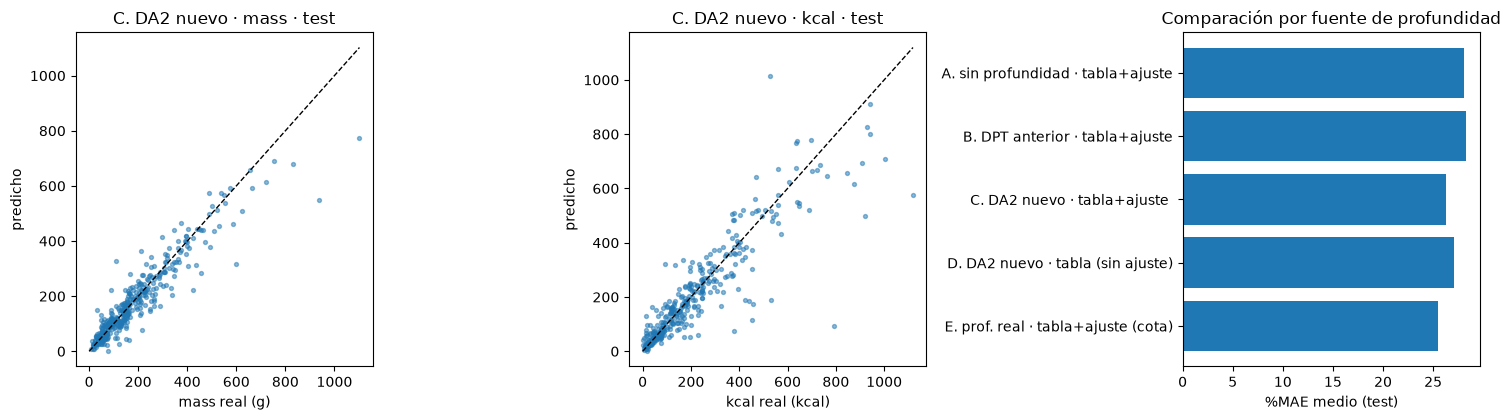

MAE mass    :   33.9 g
MAE kcal    :   51.9 kcal
MAE fat     :    3.6 g
MAE carb    :    4.3 g
MAE protein :    4.8 g


In [15]:
# ---- Variante final: dispersión real frente a predicho en el test ----
best_run = min(RESULTS[NAME_FINAL], key=lambda r: r["val"])
yhat = best_run["pred"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, k in zip(ax[:2], [0, 1]):
    ok = np.ones(len(YTE), bool) if k == 0 else ~BAD_TE
    a.scatter(YTE[ok, k], yhat[ok, k], s=8, alpha=0.5)
    lim = max(YTE[ok, k].max(), yhat[ok, k].max()); a.plot([0, lim], [0, lim], "k--", lw=1)
    a.set_xlabel(f"{TARGETS[k]} real ({UNITS[k]})"); a.set_ylabel("predicho"); a.set_title(f"{NAME_FINAL.split('·')[0].strip()} · {TARGETS[k]} · test")
names = [n for n, _ in RESULTS.items()]
means = [np.mean([metrics_masked(YTE, r["pred"], BAD_TE)[0].mean() for r in RESULTS[n]]) for n in names]
ax[2].barh([n.split(" ← ")[0] for n in names], means); ax[2].set_xlabel("%MAE medio (test)"); ax[2].invert_yaxis()
ax[2].set_title("Comparación por fuente de profundidad"); plt.tight_layout(); plt.show()

for t_, m_, u_ in zip(TARGETS, metrics_masked(YTE, yhat, BAD_TE)[1], UNITS):
    print(f"MAE {t_:8s}: {m_:6.1f} {u_}")

## 9. Inferencia sobre una foto

`predict_photo` ejecuta **todo el pipeline desde la imagen** (B1 → regiones → cabeza CLIP → profundidad afinada → cabeza nutricional) y devuelve una tabla por región (clase, probabilidad, gramos y macros) y los totales. Solo necesita la foto RGB. Con `depth_gt_dir` usa la profundidad real, para depurar.

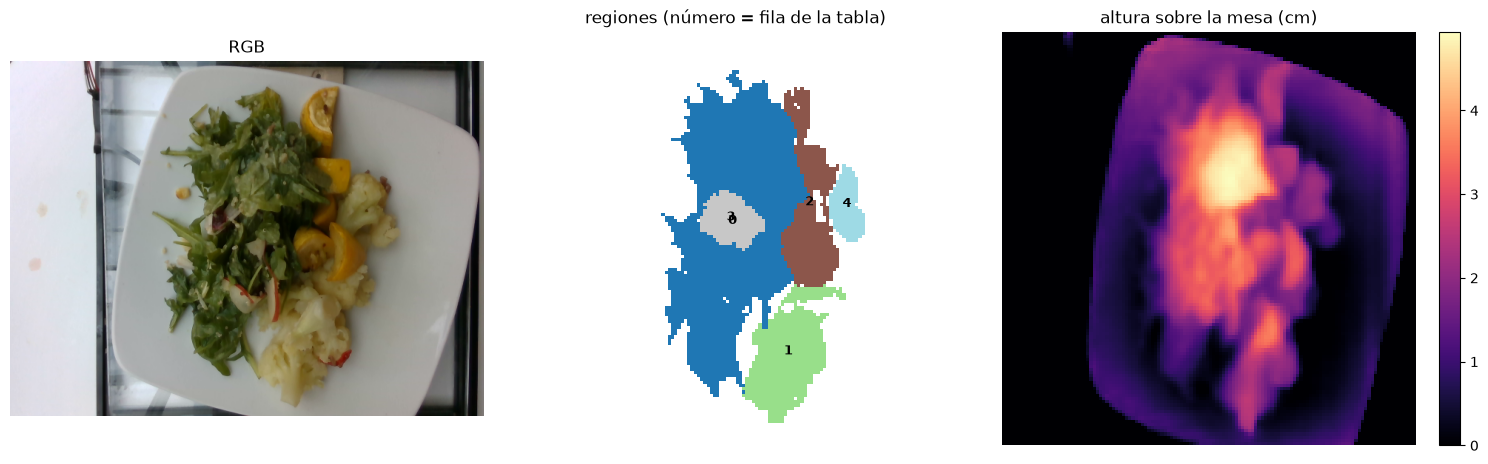

predicho: {'mass': 240.6999969482422, 'kcal': 111.4000015258789, 'fat': 6.199999809265137, 'carb': 12.399999618530273, 'protein': 4.400000095367432}
real    : {'mass': 312.0, 'kcal': 164.2, 'fat': 10.1, 'carb': 16.3, 'protein': 4.6}


,region,clase,prob_clase,area_pct,altura_cm,gramos,kcal,grasa_g,carb_g,prot_g
0,0,leafy greens,0.96,14.7,2.64,47.8,56.9,4.7,3.3,1.6
1,1,cauliflower,0.99,4.3,2.00,68.5,17.3,0.2,3.4,1.1
2,2,squash,0.91,3.6,2.29,81.8,17.5,0.3,3.2,0.8
3,3,leafy greens,0.56,1.5,3.37,13.4,12.4,0.9,1.0,0.5
4,4,cauliflower,1.00,1.1,1.54,29.3,7.4,0.1,1.5,0.5


In [16]:
FINAL = dict(model=best_run["model"], norm=best_run["norm"])

@torch.no_grad()
def predict_photo(img_path, final=FINAL, show=True, depth_gt_dir=None):
    pil = Image.open(img_path).convert("RGB"); img = np.array(pil)
    a = stage_a(img); n = a["n"]
    probs = np.zeros((R_MAX, K), np.float32)
    if n: probs[:n] = clip_head_probs(a["emb"][:n])
    depth = depth_from_gt(depth_gt_dir) if depth_gt_dir is not None else depth_from_pil(pil)
    G, M, GL, height = region_features(a["rm"], a["bg"], depth, n, return_height=True)
    probs = probs * M[:, None]

    Pn, Gn, Mn, GLn = apply_norm(probs[None], G[None], M[None], GL[None], final["norm"])
    t = lambda x: torch.from_numpy(x).to(DEVICE)
    out = final["model"].eval()(t(Pn), t(Gn), t(GLn), t(Mn))
    grams = out["grams"][0].cpu().numpy(); dens = out["dens"][0].cpu().numpy(); total = out["total"][0].cpu().numpy()

    rows = []
    for r in range(R_MAX):
        if not M[r]: continue
        c = int(probs[r].argmax())
        rows.append(dict(region=r, clase=CLASSES[1 + c], prob_clase=round(float(probs[r, c]), 2),
                         area_pct=round(float(G[r, 0] * 100), 1), altura_cm=round(float(G[r, 1]), 2),
                         gramos=round(float(grams[r]), 1), kcal=round(float(grams[r] * dens[r, 0]), 1),
                         grasa_g=round(float(grams[r] * dens[r, 1]), 1), carb_g=round(float(grams[r] * dens[r, 2]), 1),
                         prot_g=round(float(grams[r] * dens[r, 3]), 1)))
    table = pd.DataFrame(rows)
    totals = {k: float(round(v, 1)) for k, v in zip(TARGETS, total)}

    if show:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
        ax[0].imshow(img); ax[0].set_title("RGB"); ax[0].axis("off")
        ax[1].imshow(np.ma.masked_equal(a["rm"], 0), cmap="tab20", interpolation="nearest")
        for r in range(n):
            yy, xx = np.nonzero(a["rm"] == r + 1)
            if len(yy): ax[1].text(xx.mean(), yy.mean(), str(r), color="k", ha="center", fontsize=9, weight="bold")
        ax[1].set_title("regiones (número = fila de la tabla)"); ax[1].axis("off")
        im = ax[2].imshow(height, cmap="magma"); ax[2].set_title("altura sobre la mesa (cm)"); ax[2].axis("off")
        plt.colorbar(im, ax=ax[2], fraction=0.046); plt.tight_layout(); plt.show()
    return table, totals

dish_demo = dishes[IDX["test"][-1]]                      # un plato que la profundidad nunca vio
table, totals = predict_photo(img_root / dish_demo / "rgb.png")
real = {k: float(round(v, 1)) for k, v in zip(TARGETS, df.set_index("dish_id").loc[dish_demo, TARGETS])}
print("predicho:", totals); print("real    :", real)
table

## 10. Guardar el pipeline final

El paquete guarda los pesos de la cabeza nutricional, la **normalización** (sin ella falla en silencio), la tabla nutricional, la lista de clases y las rutas de los archivos que necesita. **Para correr el pipeline en otro equipo hacen falta, además del paquete:**

1. SegFormer‑B1 (`mit-b1/`)
2. Los tres `cabeza_clip_A_s*.pt`
3. La carpeta `entrega/` del modelo de profundidad
4. CLIP‑L/14 (se descarga de Hugging Face)

`load_final_pipeline` reconstruye la cabeza nutricional; el resto de etapas son las funciones de las Partes 3 a 5.

In [17]:
pkg = dict(state=best_run["model"].state_dict(), norm=best_run["norm"], cfg=CFG, dens_mode="table_ft", table=DENS_TABLE,
           classes=CLASSES, n_classes=K, head_files=[Path(f).name for f in HEAD_FILES], clip_name=CLIP_NAME, targets=TARGETS,
           depth=dict(dir=str(DEPTH_DIR), key=DEPTH_CFG["key"], run=DEPTH_CFG.get("info", {}).get("run"), tta=True),
           geometry=dict(S=S, SEG_INPUT=SEG_INPUT, MIN_REGION_PX=MIN_REGION_PX, R_MAX=R_MAX, BG_ID=BG_ID),
           entrenamiento=dict(n_train=int(len(IDX["train"])), excluidos_etiqueta_invalida="kcal<5 y masa>20 g"))
path = CACHE_DIR / "pipeline_nutricion_final.pt"
torch.save(pkg, path)
print("guardado:", path)

def load_final_pipeline(path=path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = NutritionHead(ck["n_classes"], ck["norm"]["prior"], ck["cfg"]["hidden"], ck["cfg"]["emb"], ck["cfg"]["drop"],
                      True, dens_mode=ck["dens_mode"], table=ck["table"]).to(DEVICE)
    m.load_state_dict(ck["state"]); return dict(model=m.eval(), norm=ck["norm"]), ck

# prueba de ida y vuelta: el paquete cargado debe dar el mismo resultado
final2, _ = load_final_pipeline()
_, totals2 = predict_photo(img_root / dish_demo / "rgb.png", final=final2, show=False)
print("coincide con la predicción original:", np.allclose(list(totals2.values()), list(totals.values()), atol=0.2), totals2)

guardado: pipeline_cache\pipeline_nutricion_final.pt
coincide con la predicción original: True {'mass': 240.6999969482422, 'kcal': 111.4000015258789, 'fat': 6.199999809265137, 'carb': 12.399999618530273, 'protein': 4.400000095367432}


## 11. Cómo leer los resultados y qué falta

**Qué mirar, en orden**
1. **Variante C frente a A (bootstrap):** si el intervalo queda por debajo de 0, el modelo de profundidad nuevo **sí** aporta al pipeline. En el notebook anterior el DPT no se distinguía de no usar profundidad.
2. **C frente a B:** cuánto mejora el modelo nuevo respecto al DPT anterior, ya dentro del pipeline.
3. **C frente a E:** la brecha que queda con la profundidad real. Es lo máximo que aún se podría ganar mejorando la profundidad.
4. **D frente a C:** si el ajuste sigue ayudando con la nueva profundidad.
5. **Tabla de altura:** debería mostrar una correlación mucho mayor y un error en cm mucho menor que el DPT anterior (antes: corr 0.52 y error de 1.86 cm).

**Limitaciones**
- **Solo hay verdad de terreno por plato**, no por región. Revisa a ojo la tabla de `predict_photo` en varios platos.
- **Dominio:** la profundidad se afinó con una cámara fija a ~36 cm de la mesa. Con fotos de celular a otra distancia o ángulo, la escala métrica no está garantizada; hay que validarlo aparte antes de prometer gramos.
- **Etiquetas:** los platos con kcal ≈ 0 y comida visible se excluyen del entrenamiento y de las métricas de kcal y macros. Si alguno era una bebida genuina sin calorías, el modelo no aprende ese caso.
- **Tabla nutricional:** clases fusionadas o sin coincidencia por nombre usan una aproximación, y el ajuste `exp(Δ)` las corrige solo en parte. Revisa las clases con `Δ` grande.
- **El test es pequeño** (cientos de platos): las diferencias de menos de ~1 punto pueden ser ruido aunque el bootstrap las marque.

**Siguientes pasos naturales**
- Si la brecha C → E sigue siendo grande, el cuello de botella sigue en la profundidad (por ejemplo, ajustar el plano de la mesa con un ajuste plano en lugar de la mediana del fondo).
- Si C ≈ E, el límite está en la clase y la densidad, no en la profundidad: más etiquetado de clases débiles o afinar B1.
- Cuando integres la app, usa `predict_photo` como referencia de la secuencia de llamadas.